Image Shape : (917, 1880, 3)
Image Size  : 1880 x 917 pixels


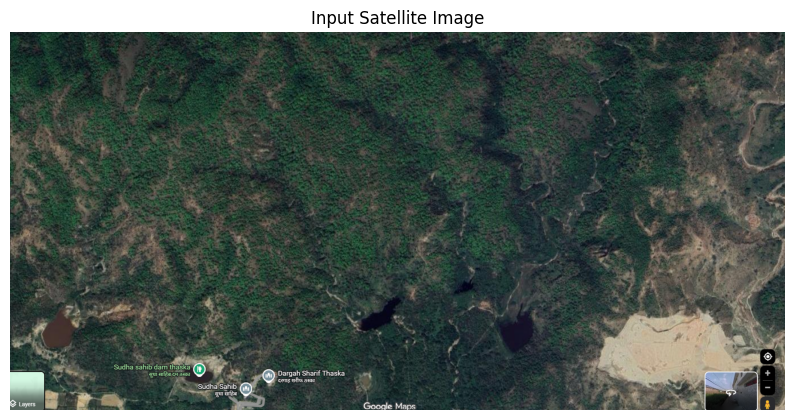

find_start_end() defined — will be used in Phase 4 after cost grid is ready.
Auto-detects nearest passable (non-water) pixel from corners.


In [5]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

# ── CONFIG ──────────────────────────────────────────────
IMAGE_PATH = r"F:\resume project\path project\input\map_image.png"
# ────────────────────────────────────────────────────────

# Load image
image = cv2.imread(IMAGE_PATH)
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

print(f"Image Shape : {image.shape}")
print(f"Image Size  : {image.shape[1]} x {image.shape[0]} pixels")

# Display original
plt.figure(figsize=(10, 6))
plt.imshow(image_rgb)
plt.title("Input Satellite Image")
plt.axis('off')
plt.show()
# ── AUTO START/END DETECTION ────────────────────────────
# Finds nearest non-water pixel to top-left and bottom-right corners
# This runs AFTER terrain classification (cost_grid must exist)
# Shown here for reference — actual call happens in Phase 4

def find_start_end(grid):
    """Finds nearest non-water pixel to top-left and bottom-right corners."""
    H, W = grid.shape

    def nearest_passable(r, c):
        for d in range(max(H, W)):
            for dr in range(-d, d + 1):
                for dc in range(-d, d + 1):
                    nr, nc = r + dr, c + dc
                    if 0 <= nr < H and 0 <= nc < W and grid[nr, nc] < 9999:
                        return (nr, nc)
        return (r, c)  # fallback

    start = nearest_passable(10, 10)        # near top-left
    end   = nearest_passable(H - 10, W - 10)  # near bottom-right
    return start, end

print("find_start_end() defined — will be used in Phase 4 after cost grid is ready.")
print("Auto-detects nearest passable (non-water) pixel from corners.")
